In [ ]:
import json, os, sys, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/thinthie/Project-ML-Praktisi-kel-21-kasus-3/main/raw_data.csv"
if not os.path.exists("raw_data.csv"):
    urllib.request.urlretrieve(DATA_URL, "raw_data.csv")

os.makedirs("src", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
open("src/__init__.py", "a").close()
if "" not in sys.path:
    sys.path.insert(0, "")

RANDOM_STATE = 42
df = pd.read_csv("raw_data.csv", sep=";")
print(f"{len(df):,} baris, {df.shape[1]} kolom")
df.head()

79,652 baris, 11 kolom


,motor_id,tipe_motor,lokasi,hari_operasi,beban_pct,arus_A,tegangan_V,suhu_belitan_C,getaran_rms_mm_s,kecepatan_rpm,rul_hari
0,M-001,5.5kW,Plant Purwakarta,0,95.4,10.47,376.5,337.2,2.08,1472.0,251
1,M-001,5.5kW,Plant Purwakarta,1,82.1,8.81,382.0,332.8,2.14,1476.0,250
2,M-001,5.5kW,Plant Purwakarta,2,82.3,8.74,383.8,328.0,2.00,1474.0,249
3,M-001,5.5kW,Plant Purwakarta,3,80.7,8.42,377.0,333.3,2.03,1476.0,248
4,M-001,5.5kW,Plant Purwakarta,4,89.3,9.46,384.5,333.2,2.06,1477.0,247


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79652 entries, 0 to 79651
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   motor_id          79652 non-null  object 
 1   tipe_motor        79652 non-null  object 
 2   lokasi            79652 non-null  object 
 3   hari_operasi      79652 non-null  int64  
 4   beban_pct         79652 non-null  float64
 5   arus_A            78050 non-null  float64
 6   tegangan_V        79652 non-null  float64
 7   suhu_belitan_C    78858 non-null  float64
 8   getaran_rms_mm_s  79652 non-null  float64
 9   kecepatan_rpm     79652 non-null  float64
 10  rul_hari          79652 non-null  int64  
dtypes: float64(6), int64(2), object(3)
memory usage: 6.7+ MB


In [ ]:

# ==========================================
# 1. PEMERIKSAAN KUALITAS DATA
# ==========================================

print("UKURAN DATA")
print(df.shape)

print("\nJUMLAH MOTOR UNIK")
print(df["motor_id"].nunique())

print("\nJUMLAH DATA KOSONG")
print(df.isnull().sum())

print("\nJUMLAH BARIS DUPLIKAT")
print(df.duplicated().sum())

print("\nJUMLAH DATA PER TIPE MOTOR")
print(df["tipe_motor"].value_counts())

print("\nJUMLAH DATA PER LOKASI")
print(df["lokasi"].value_counts())

print("\nSTATISTIK DESKRIPTIF")
display(df.describe().T)


UKURAN DATA
(79652, 11)

JUMLAH MOTOR UNIK
1147

JUMLAH DATA KOSONG
motor_id               0
tipe_motor             0
lokasi                 0
hari_operasi           0
beban_pct              0
arus_A              1602
tegangan_V             0
suhu_belitan_C       794
getaran_rms_mm_s       0
kecepatan_rpm          0
rul_hari               0
dtype: int64

JUMLAH BARIS DUPLIKAT
493

JUMLAH DATA PER TIPE MOTOR
tipe_motor
11kW      35041
5.5kW     29211
22kW      13812
22KW        549
11 kW       533
5,5 kW      506
Name: count, dtype: int64

JUMLAH DATA PER LOKASI
lokasi
Plant Cikarang      29765
Plant Purwakarta    25623
Plant Karawang      24264
Name: count, dtype: int64

STATISTIK DESKRIPTIF


,count,mean,std,min,25%,50%,75%,max
hari_operasi,79652.0,149.771481,102.894696,0.00,67.00,135.00,216.00,543.00
beban_pct,79652.0,74.690018,12.435699,38.90,64.90,74.40,84.40,110.00
arus_A,78050.0,15.954332,8.746818,4.13,8.78,14.22,19.31,47.24
tegangan_V,79652.0,379.997084,3.996098,363.40,377.30,380.00,382.70,396.80
suhu_belitan_C,78858.0,153.037131,127.737506,39.60,61.40,70.60,330.80,372.00
getaran_rms_mm_s,79652.0,2.998297,1.428476,-1.00,2.06,2.35,3.48,8.01
kecepatan_rpm,79652.0,1470.669035,5.853770,1451.00,1467.00,1472.00,1475.00,1485.00
rul_hari,79652.0,149.743095,102.930091,0.00,66.00,135.00,217.00,543.00


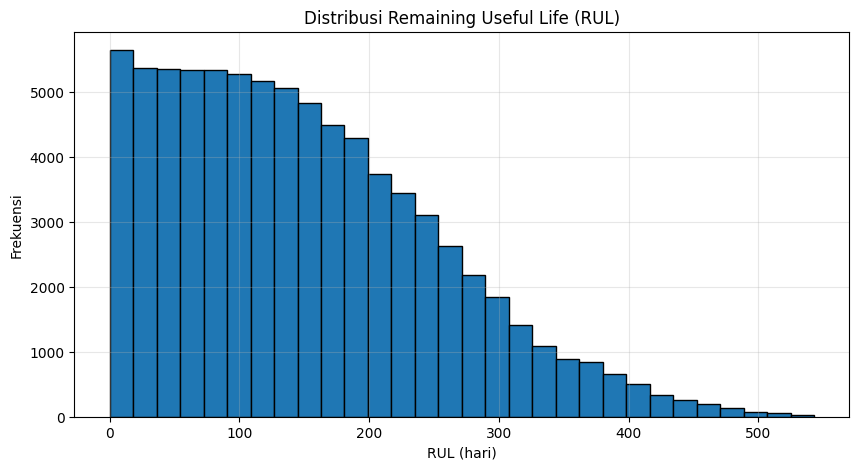

Nilai RUL minimum: 0
Nilai RUL maksimum: 543
Rata-rata RUL: 149.74309496308945


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["rul_hari"], bins=30, edgecolor="black")
plt.title("Distribusi Remaining Useful Life (RUL)")
plt.xlabel("RUL (hari)")
plt.ylabel("Frekuensi")
plt.grid(alpha=0.3)
plt.show()

print("Nilai RUL minimum:", df["rul_hari"].min())
print("Nilai RUL maksimum:", df["rul_hari"].max())
print("Rata-rata RUL:", df["rul_hari"].mean())


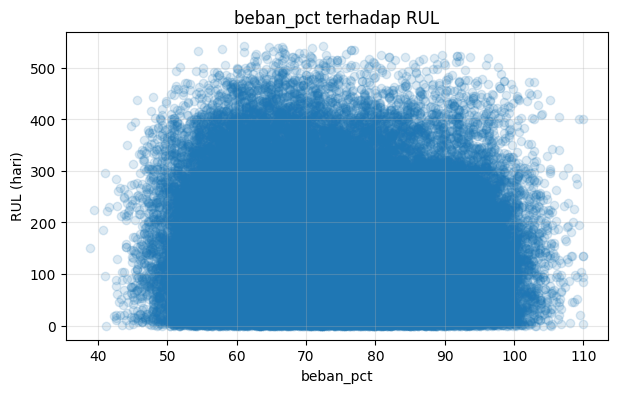

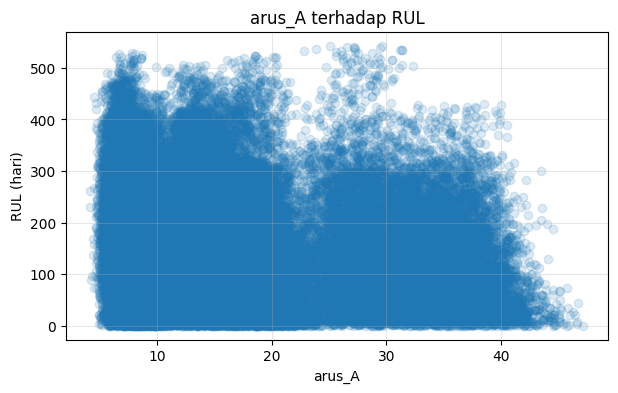

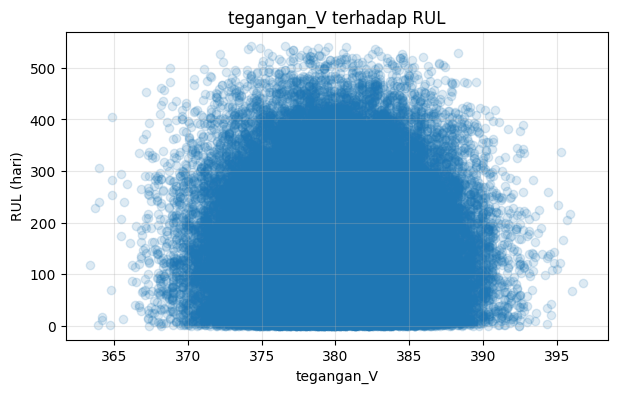

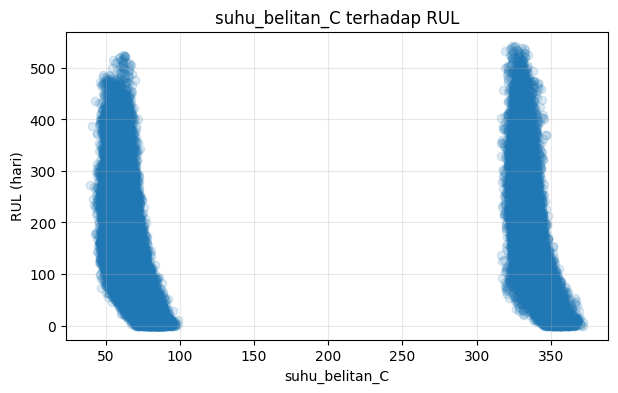

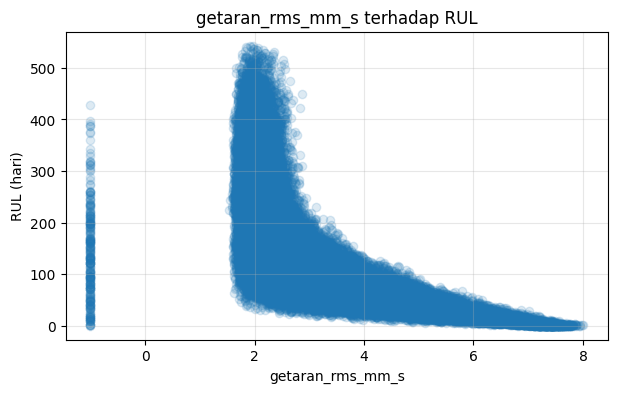

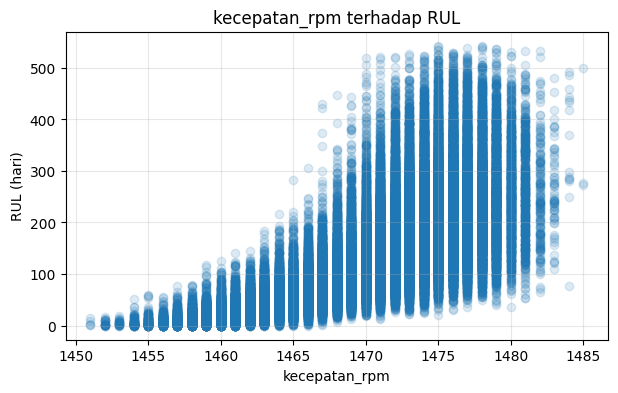

In [ ]:

sensor_cols = [
    "beban_pct",
    "arus_A",
    "tegangan_V",
    "suhu_belitan_C",
    "getaran_rms_mm_s",
    "kecepatan_rpm"
]

for col in sensor_cols:
    plt.figure(figsize=(7, 4))
    plt.scatter(df[col], df["rul_hari"], alpha=0.15)
    plt.title(f"{col} terhadap RUL")
    plt.xlabel(col)
    plt.ylabel("RUL (hari)")
    plt.grid(alpha=0.3)
    plt.show()


In [ ]:
# ==========================================
# 2. DATA CLEANING
# ==========================================

df_clean = df.copy()

# 1. Menghapus baris duplikat
print("Duplikat sebelum:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("Duplikat sesudah:", df_clean.duplicated().sum())

# 2. Menyeragamkan penulisan tipe motor
df_clean["tipe_motor"] = (
    df_clean["tipe_motor"]
    .str.strip()
    .str.lower()
    .str.replace(" ", "", regex=False)
    .str.replace(",", ".", regex=False)
)

# Menyeragamkan variasi penulisan
df_clean["tipe_motor"] = df_clean["tipe_motor"].replace({
    "5.5kw": "5.5kW",
    "11kw": "11kW",
    "22kw": "22kW"
})

# 3. Memeriksa nilai yang tidak masuk akal
print("\nJumlah nilai RUL negatif:", (df_clean["rul_hari"] < 0).sum())
print("Jumlah beban di luar 0-100:",
      ((df_clean["beban_pct"] < 0) | (df_clean["beban_pct"] > 100)).sum())

# 4. Memeriksa kembali hasil cleaning
print("\nUkuran data setelah cleaning:", df_clean.shape)
print("\nKategori tipe motor:")
print(df_clean["tipe_motor"].value_counts())

print("\nMissing values:")
print(df_clean.isnull().sum())

Duplikat sebelum: 493
Duplikat sesudah: 0

Jumlah nilai RUL negatif: 0
Jumlah beban di luar 0-100: 788

Ukuran data setelah cleaning: (79159, 11)

Kategori tipe motor:
tipe_motor
11kW     35346
5.5kW    29542
22kW     14271
Name: count, dtype: int64

Missing values:
motor_id               0
tipe_motor             0
lokasi                 0
hari_operasi           0
beban_pct              0
arus_A              1588
tegangan_V             0
suhu_belitan_C       787
getaran_rms_mm_s       0
kecepatan_rpm          0
rul_hari               0
dtype: int64


In [ ]:
# ==========================================
# 3. INVESTIGASI NILAI BEBAN
# ==========================================

# Pisahkan nilai beban yang tidak normal
beban_negatif = df_clean[df_clean["beban_pct"] < 0]
beban_lebih = df_clean[df_clean["beban_pct"] > 100]

print("Jumlah beban negatif:", len(beban_negatif))
print("Jumlah beban di atas 100%:", len(beban_lebih))

print("\nNilai beban paling kecil:")
print(df_clean["beban_pct"].min())

print("\nNilai beban paling besar:")
print(df_clean["beban_pct"].max())

print("\nContoh beban negatif:")
display(beban_negatif[["motor_id", "hari_operasi", "beban_pct"]].head(10))

print("\nContoh beban di atas 100%:")
display(beban_lebih[["motor_id", "hari_operasi", "beban_pct"]].head(10))

print("\nStatistik beban:")
display(df_clean["beban_pct"].describe())

Jumlah beban negatif: 0
Jumlah beban di atas 100%: 788

Nilai beban paling kecil:
38.9

Nilai beban paling besar:
110.0

Contoh beban negatif:


,motor_id,hari_operasi,beban_pct



Contoh beban di atas 100%:


,motor_id,hari_operasi,beban_pct
147,M-001,150,103.2
219,M-001,223,100.7
517,M-003,20,102.9
534,M-003,37,100.2
609,M-003,113,103.5
628,M-003,132,105.7
655,M-003,160,100.9
686,M-003,194,100.6
699,M-003,206,102.9
780,M-003,287,104.5



Statistik beban:


,beban_pct
count,79159.000000
mean,74.690806
std,12.436756
min,38.900000
25%,64.900000
50%,74.400000
75%,84.400000
max,110.000000


In [ ]:
# ==========================================
# 4. FEATURE ENGINEERING
# ==========================================

df_model = df_clean.copy()

# Fitur indikator overload
df_model["indikator_overload"] = (
    df_model["beban_pct"] > 100
).astype(int)

# Fitur indikator beban tinggi
df_model["indikator_beban_tinggi"] = (
    df_model["beban_pct"] >= 85
).astype(int)

# Fitur indikator suhu tinggi
df_model["indikator_suhu_tinggi"] = (
    df_model["suhu_belitan_C"] > 80
).astype(int)

# Fitur indikator getaran tinggi
df_model["indikator_getaran_tinggi"] = (
    df_model["getaran_rms_mm_s"] > 4.5
).astype(int)

print("Ukuran data:", df_model.shape)

print("\nJumlah motor overload:")
print(df_model["indikator_overload"].sum())

print("\nJumlah motor dengan beban tinggi:")
print(df_model["indikator_beban_tinggi"].sum())

print("\nContoh hasil feature engineering:")
display(df_model.head())

Ukuran data: (79159, 15)

Jumlah motor overload:
788

Jumlah motor dengan beban tinggi:
18852

Contoh hasil feature engineering:


,motor_id,tipe_motor,lokasi,hari_operasi,beban_pct,arus_A,tegangan_V,suhu_belitan_C,getaran_rms_mm_s,kecepatan_rpm,rul_hari,indikator_overload,indikator_beban_tinggi,indikator_suhu_tinggi,indikator_getaran_tinggi
0,M-001,5.5kW,Plant Purwakarta,0,95.4,10.47,376.5,337.2,2.08,1472.0,251,0,1,1,0
1,M-001,5.5kW,Plant Purwakarta,1,82.1,8.81,382.0,332.8,2.14,1476.0,250,0,0,1,0
2,M-001,5.5kW,Plant Purwakarta,2,82.3,8.74,383.8,328.0,2.00,1474.0,249,0,0,1,0
3,M-001,5.5kW,Plant Purwakarta,3,80.7,8.42,377.0,333.3,2.03,1476.0,248,0,0,1,0
4,M-001,5.5kW,Plant Purwakarta,4,89.3,9.46,384.5,333.2,2.06,1477.0,247,0,1,1,0


In [ ]:
# ==========================================
# 5. GROUP TRAIN TEST SPLIT
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

X = df_model.drop(columns=["rul_hari", "motor_id"])
y = df_model["rul_hari"]
groups = df_model["motor_id"]

# Pembagian 80% training dan 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("Jumlah motor training:", groups_train.nunique())
print("Jumlah motor testing:", groups_test.nunique())

print(
    "Motor yang muncul di kedua kelompok:",
    len(set(groups_train) & set(groups_test))
)

Jumlah data training: 63315
Jumlah data testing: 15844
Jumlah motor training: 917
Jumlah motor testing: 230
Motor yang muncul di kedua kelompok: 0


In [ ]:
# ==========================================
# 6. PEMERIKSAAN SENSOR
# ==========================================

kolom_sensor = [
    "suhu_belitan_C",
    "getaran_rms_mm_s",
    "arus_A",
    "tegangan_V",
    "kecepatan_rpm",
    "beban_pct"
]

print("STATISTIK SENSOR")
display(df_clean[kolom_sensor].describe().T)

print("\nJUMLAH SUHU DI ATAS 100°C:")
print((df_clean["suhu_belitan_C"] > 100).sum())

print("\nJUMLAH SUHU DI ATAS 150°C:")
print((df_clean["suhu_belitan_C"] > 150).sum())

print("\nJUMLAH GETARAN DI ATAS 4.5 mm/s:")
print((df_clean["getaran_rms_mm_s"] > 4.5).sum())

print("\nJUMLAH SUHU KOSONG:")
print(df_clean["suhu_belitan_C"].isna().sum())

STATISTIK SENSOR


,count,mean,std,min,25%,50%,75%,max
suhu_belitan_C,78372.0,153.047327,127.742298,39.60,61.40,70.60,330.80,372.00
getaran_rms_mm_s,79159.0,2.998385,1.428394,-1.00,2.06,2.35,3.48,8.01
arus_A,77571.0,15.952904,8.747596,4.13,8.78,14.22,19.31,47.24
tegangan_V,79159.0,379.998092,3.996418,363.40,377.30,380.00,382.70,396.80
kecepatan_rpm,79159.0,1470.667543,5.854148,1451.00,1467.00,1472.00,1475.00,1485.00
beban_pct,79159.0,74.690806,12.436756,38.90,64.90,74.40,84.40,110.00



JUMLAH SUHU DI ATAS 100°C:
25201

JUMLAH SUHU DI ATAS 150°C:
25201

JUMLAH GETARAN DI ATAS 4.5 mm/s:
12469

JUMLAH SUHU KOSONG:
787


In [ ]:
# ==========================================
# 7. INVESTIGASI ANOMALI SENSOR
# ==========================================

# A. Distribusi suhu
print("DISTRIBUSI SUHU")
print(df_clean["suhu_belitan_C"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

print("\nJumlah suhu berdasarkan rentang:")
print(pd.cut(
    df_clean["suhu_belitan_C"],
    bins=[0, 50, 80, 100, 150, 250, 400],
    right=True
).value_counts().sort_index())

# B. Contoh suhu tinggi dan rendah
print("\nCONTOH SUHU DI BAWAH 100°C")
display(
    df_clean.loc[
        df_clean["suhu_belitan_C"] < 100,
        ["motor_id", "tipe_motor", "lokasi",
         "hari_operasi", "suhu_belitan_C", "rul_hari"]
    ].head(10)
)

print("\nCONTOH SUHU DI ATAS 300°C")
display(
    df_clean.loc[
        df_clean["suhu_belitan_C"] > 300,
        ["motor_id", "tipe_motor", "lokasi",
         "hari_operasi", "suhu_belitan_C", "rul_hari"]
    ].head(10)
)

# C. Ringkasan suhu berdasarkan tipe motor
print("\nSUHU BERDASARKAN TIPE MOTOR")
display(
    df_clean.groupby("tipe_motor")["suhu_belitan_C"]
    .agg(["count", "mean", "median", "min", "max"])
)

# D. Pemeriksaan getaran negatif
print("\nJUMLAH GETARAN NEGATIF:")
print((df_clean["getaran_rms_mm_s"] < 0).sum())

print("\nCONTOH GETARAN NEGATIF:")
display(
    df_clean.loc[
        df_clean["getaran_rms_mm_s"] < 0,
        ["motor_id", "hari_operasi",
         "getaran_rms_mm_s", "rul_hari"]
    ].head(10)
)

DISTRIBUSI SUHU
count    78372.000000
mean       153.047327
std        127.742298
min         39.600000
10%         56.100000
25%         61.400000
50%         70.600000
75%        330.800000
90%        341.800000
95%        348.000000
99%        356.600000
max        372.000000
Name: suhu_belitan_C, dtype: float64

Jumlah suhu berdasarkan rentang:
suhu_belitan_C
(0, 50]         999
(50, 80]      48395
(80, 100]      3777
(100, 150]        0
(150, 250]        0
(250, 400]    25201
Name: count, dtype: int64

CONTOH SUHU DI BAWAH 100°C


,motor_id,tipe_motor,lokasi,hari_operasi,suhu_belitan_C,rul_hari
248,M-002,5.5kW,Plant Karawang,0,61.7,252
249,M-002,5.5kW,Plant Karawang,1,59.2,251
250,M-002,5.5kW,Plant Karawang,2,60.0,250
251,M-002,5.5kW,Plant Karawang,3,56.3,249
252,M-002,5.5kW,Plant Karawang,4,60.9,248
253,M-002,5.5kW,Plant Karawang,5,62.1,247
254,M-002,5.5kW,Plant Karawang,6,62.0,246
255,M-002,5.5kW,Plant Karawang,7,63.4,245
256,M-002,5.5kW,Plant Karawang,8,59.5,244
257,M-002,5.5kW,Plant Karawang,9,60.4,243



CONTOH SUHU DI ATAS 300°C


,motor_id,tipe_motor,lokasi,hari_operasi,suhu_belitan_C,rul_hari
0,M-001,5.5kW,Plant Purwakarta,0,337.2,251
1,M-001,5.5kW,Plant Purwakarta,1,332.8,250
2,M-001,5.5kW,Plant Purwakarta,2,328.0,249
3,M-001,5.5kW,Plant Purwakarta,3,333.3,248
4,M-001,5.5kW,Plant Purwakarta,4,333.2,247
5,M-001,5.5kW,Plant Purwakarta,5,330.5,246
6,M-001,5.5kW,Plant Purwakarta,6,338.0,245
7,M-001,5.5kW,Plant Purwakarta,7,332.2,244
8,M-001,5.5kW,Plant Purwakarta,8,338.0,243
9,M-001,5.5kW,Plant Purwakarta,9,339.8,242



SUHU BERDASARKAN TIPE MOTOR


,count,mean,median,min,max
tipe_motor,,,,,
11kW,34988,163.218112,72.2,39.6,372.0
22kW,14147,131.831053,68.4,43.2,370.0
5.5kW,29237,151.141906,70.1,40.7,370.2



JUMLAH GETARAN NEGATIF:
239

CONTOH GETARAN NEGATIF:


,motor_id,hari_operasi,getaran_rms_mm_s,rul_hari
106,M-001,107,-1.0,144
292,M-002,44,-1.0,208
354,M-002,105,-1.0,147
611,M-003,115,-1.0,203
1073,M-004,263,-1.0,127
1731,M-007,142,-1.0,127
2367,M-009,165,-1.0,75
3070,M-013,61,-1.0,109
3278,M-014,96,-1.0,235
3534,M-015,22,-1.0,150


In [ ]:
# ==========================================
# 8. FINAL CLEANING & GROUP SPLIT
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

df_model = df_clean.copy()

# Nilai -1 pada RMS getaran tidak valid secara fisik
df_model.loc[
    df_model["getaran_rms_mm_s"] < 0,
    "getaran_rms_mm_s"
] = np.nan

# Fitur asli; motor_id hanya digunakan untuk pembagian kelompok
feature_cols = [
    "tipe_motor",
    "lokasi",
    "hari_operasi",
    "beban_pct",
    "arus_A",
    "tegangan_V",
    "suhu_belitan_C",
    "getaran_rms_mm_s",
    "kecepatan_rpm"
]

X = df_model[feature_cols].copy()
y = df_model["rul_hari"].copy()
groups = df_model["motor_id"].copy()

# Split berdasarkan motor_id
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("Jumlah motor training:", groups_train.nunique())
print("Jumlah motor testing:", groups_test.nunique())
print("Irisan motor:", len(set(groups_train) & set(groups_test)))

print("\nJumlah getaran missing setelah cleaning:",
      df_model["getaran_rms_mm_s"].isna().sum())

Jumlah data training: 63315
Jumlah data testing: 15844
Jumlah motor training: 917
Jumlah motor testing: 230
Irisan motor: 0

Jumlah getaran missing setelah cleaning: 239


In [ ]:
# ==========================================
# 9. BASELINE LINEAR REGRESSION
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Pisahkan fitur numerik dan kategorikal
numeric_features = [
    "hari_operasi",
    "beban_pct",
    "arus_A",
    "tegangan_V",
    "suhu_belitan_C",
    "getaran_rms_mm_s",
    "kecepatan_rpm"
]

categorical_features = [
    "tipe_motor",
    "lokasi"
]

# Preprocessing fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Gabungkan preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Pipeline baseline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Training
baseline_model.fit(X_train, y_train)

# Prediksi
y_pred_baseline = baseline_model.predict(X_test)

# Evaluasi MAE
mae_all = mean_absolute_error(y_test, y_pred_baseline)

# Evaluasi khusus RUL <= 60 hari
mask_60 = y_test <= 60

mae_60 = mean_absolute_error(
    y_test[mask_60],
    y_pred_baseline[mask_60]
)

print("HASIL BASELINE LINEAR REGRESSION")
print("--------------------------------")
print(f"MAE seluruh data : {mae_all:.2f} hari")
print(f"MAE RUL <= 60    : {mae_60:.2f} hari")
print(f"Jumlah data RUL <= 60: {mask_60.sum()}")

HASIL BASELINE LINEAR REGRESSION
--------------------------------
MAE seluruh data : 50.26 hari
MAE RUL <= 60    : 34.20 hari
Jumlah data RUL <= 60: 3556


In [ ]:
# ==========================================
# 10. RANDOM FOREST REGRESSOR
# ==========================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

# Gunakan preprocessing yang sama dengan baseline
rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

print("Memulai training Random Forest...")

rf_model.fit(X_train, y_train)

print("Training selesai!")

# Prediksi data testing
y_pred_rf = rf_model.predict(X_test)

# Evaluasi seluruh data
mae_rf_all = mean_absolute_error(
    y_test,
    y_pred_rf
)

# Evaluasi RUL <= 60 hari
mae_rf_60 = mean_absolute_error(
    y_test[mask_60],
    y_pred_rf[mask_60]
)

print("\nHASIL RANDOM FOREST REGRESSOR")
print("--------------------------------")
print(f"MAE seluruh data : {mae_rf_all:.2f} hari")
print(f"MAE RUL <= 60    : {mae_rf_60:.2f} hari")

Memulai training Random Forest...
Training selesai!

HASIL RANDOM FOREST REGRESSOR
--------------------------------
MAE seluruh data : 42.06 hari
MAE RUL <= 60    : 8.75 hari


In [ ]:
# ==========================================
# 11. PERBANDINGAN MODEL
# ==========================================

hasil_model = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE Seluruh Data": [
        mae_all,
        mae_rf_all
    ],
    "MAE RUL <= 60": [
        mae_60,
        mae_rf_60
    ]
})

display(
    hasil_model.sort_values(
        by="MAE RUL <= 60"
    ).reset_index(drop=True)
)

,Model,MAE Seluruh Data,MAE RUL <= 60
0,Random Forest,42.062599,8.751006
1,Linear Regression,50.256042,34.199449


In [ ]:

# ==========================================
# 12. Pembagian Train, Validation, Test
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

# Tahap 1: Sisihkan 20% motor untuk data test
split_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

trainval_idx, test_idx = next(
    split_test.split(X, y, groups)
)

X_trainval = X.iloc[trainval_idx].copy()
y_trainval = y.iloc[trainval_idx].copy()
groups_trainval = groups.iloc[trainval_idx].copy()

X_test_new = X.iloc[test_idx].copy()
y_test_new = y.iloc[test_idx].copy()
groups_test_new = groups.iloc[test_idx].copy()


# Tahap 2: Sisihkan 20% dari trainval untuk validation
# Hasilnya kira-kira 64% train, 16% validation, 20% test
split_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=43
)

train_idx, val_idx = next(
    split_val.split(X_trainval, y_trainval, groups_trainval)
)

X_train_new = X_trainval.iloc[train_idx].copy()
y_train_new = y_trainval.iloc[train_idx].copy()
groups_train_new = groups_trainval.iloc[train_idx].copy()

X_val_new = X_trainval.iloc[val_idx].copy()
y_val_new = y_trainval.iloc[val_idx].copy()
groups_val_new = groups_trainval.iloc[val_idx].copy()


# Periksa ukuran data dan jumlah motor
print("Jumlah baris:")
print("Train      :", len(X_train_new))
print("Validation :", len(X_val_new))
print("Test       :", len(X_test_new))

print("\nJumlah motor:")
print("Train      :", groups_train_new.nunique())
print("Validation :", groups_val_new.nunique())
print("Test       :", groups_test_new.nunique())

# Pastikan tidak ada motor yang muncul di dua kelompok
print("\nPemeriksaan irisan motor:")
print("Train vs Validation:",
      len(set(groups_train_new) & set(groups_val_new)))

print("Train vs Test:",
      len(set(groups_train_new) & set(groups_test_new)))

print("Validation vs Test:",
      len(set(groups_val_new) & set(groups_test_new)))


Jumlah baris:
Train      : 51517
Validation : 11798
Test       : 15844

Jumlah motor:
Train      : 733
Validation : 184
Test       : 230

Pemeriksaan irisan motor:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


In [ ]:
# ==========================================
# 13. Evaluasi model pada Validation
# ==========================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

# ==========================================
# 1. LINEAR REGRESSION (BASELINE)
# ==========================================

baseline_model_val = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

baseline_model_val.fit(X_train_new, y_train_new)

pred_lr_val = baseline_model_val.predict(X_val_new)


# ==========================================
# 2. RANDOM FOREST
# ==========================================

rf_model_val = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model_val.fit(X_train_new, y_train_new)

pred_rf_val = rf_model_val.predict(X_val_new)


# ==========================================
# 3. HITUNG MAE VALIDATION
# ==========================================

mask_val_60 = y_val_new <= 60

mae_lr_val_all = mean_absolute_error(
    y_val_new, pred_lr_val
)

mae_lr_val_60 = mean_absolute_error(
    y_val_new[mask_val_60],
    pred_lr_val[mask_val_60]
)

mae_rf_val_all = mean_absolute_error(
    y_val_new, pred_rf_val
)

mae_rf_val_60 = mean_absolute_error(
    y_val_new[mask_val_60],
    pred_rf_val[mask_val_60]
)


# ==========================================
# 4. PERBANDINGAN MODEL VALIDATION
# ==========================================

hasil_validation = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE Validation Seluruh Data": [
        mae_lr_val_all,
        mae_rf_val_all
    ],
    "MAE Validation RUL <= 60": [
        mae_lr_val_60,
        mae_rf_val_60
    ]
})

display(
    hasil_validation.sort_values(
        by="MAE Validation RUL <= 60"
    ).reset_index(drop=True)
)

print("Jumlah data validation dengan RUL <= 60:",
      mask_val_60.sum())


,Model,MAE Validation Seluruh Data,MAE Validation RUL <= 60
0,Random Forest,44.079621,10.872696
1,Linear Regression,52.575112,35.316672


Jumlah data validation dengan RUL <= 60: 2715


In [ ]:
# ==========================================
# 14. Pelatihan ulang dan evaluasi Test
# ==========================================


# ==========================================
# 1. GABUNGKAN DATA TRAIN DAN VALIDATION
# ==========================================

X_train_final = pd.concat(
    [X_train_new, X_val_new],
    axis=0
)

y_train_final = pd.concat(
    [y_train_new, y_val_new],
    axis=0
)


# ==========================================
# 2. LATIH ULANG LINEAR REGRESSION
# ==========================================

baseline_model_final = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

baseline_model_final.fit(
    X_train_final,
    y_train_final
)


# ==========================================
# 3. LATIH ULANG RANDOM FOREST
# ==========================================

rf_model_final = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model_final.fit(
    X_train_final,
    y_train_final
)


# ==========================================
# 4. PREDIKSI DATA TEST
# ==========================================

pred_lr_test = baseline_model_final.predict(X_test_new)
pred_rf_test = rf_model_final.predict(X_test_new)


# ==========================================
# 5. HITUNG MAE TEST
# ==========================================

mask_test_60 = y_test_new <= 60

mae_lr_test_all = mean_absolute_error(
    y_test_new, pred_lr_test
)

mae_lr_test_60 = mean_absolute_error(
    y_test_new[mask_test_60],
    pred_lr_test[mask_test_60]
)

mae_rf_test_all = mean_absolute_error(
    y_test_new, pred_rf_test
)

mae_rf_test_60 = mean_absolute_error(
    y_test_new[mask_test_60],
    pred_rf_test[mask_test_60]
)


# ==========================================
# 6. PERBANDINGAN HASIL TEST
# ==========================================

hasil_test = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE Test Seluruh Data": [
        mae_lr_test_all,
        mae_rf_test_all
    ],
    "MAE Test RUL <= 60": [
        mae_lr_test_60,
        mae_rf_test_60
    ]
})

display(
    hasil_test.sort_values(
        by="MAE Test RUL <= 60"
    ).reset_index(drop=True)
)

print("Jumlah data test dengan RUL <= 60:",
      mask_test_60.sum())


,Model,MAE Test Seluruh Data,MAE Test RUL <= 60
0,Random Forest,42.045665,8.724796
1,Linear Regression,50.256042,34.199449


Jumlah data test dengan RUL <= 60: 3556


In [ ]:
# ==========================================
# 15. Simpan model final dan metadata
# ==========================================


import os
import json
import joblib

# Buat folder artifacts jika belum tersedia
os.makedirs("artifacts", exist_ok=True)

# Simpan model Random Forest final
joblib.dump(
    rf_model_final,
    "artifacts/model_rul_random_forest.joblib"
)

# Simpan informasi model dan hasil evaluasi
metadata = {
    "model_name": "Random Forest Regressor",
    "target": "rul_hari",
    "features": feature_cols,

    "validation_metrics": {
        "mae_lr_all": float(mae_lr_val_all),
        "mae_lr_rul_le_60": float(mae_lr_val_60),
        "mae_rf_all": float(mae_rf_val_all),
        "mae_rf_rul_le_60": float(mae_rf_val_60)
    },

    "test_metrics": {
        "mae_lr_all": float(mae_lr_test_all),
        "mae_lr_rul_le_60": float(mae_lr_test_60),
        "mae_rf_all": float(mae_rf_test_all),
        "mae_rf_rul_le_60": float(mae_rf_test_60)
    },

    "data_split": {
        "method": "GroupShuffleSplit",
        "train_approx": 0.64,
        "validation_approx": 0.16,
        "test_approx": 0.20,
        "test_random_state": 42,
        "validation_random_state": 43,
        "train_motors": int(groups_train_new.nunique()),
        "validation_motors": int(groups_val_new.nunique()),
        "test_motors": int(groups_test_new.nunique())
    }
}

with open("artifacts/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# Jadikan satu file ZIP agar mudah diunduh
shutil.make_archive("model_rul_random_forest", "zip", "artifacts")

print("Model final berhasil disimpan!")
print("Lokasi: artifacts/model_rul_random_forest.joblib")
print("Metadata berhasil disimpan!")


Model final berhasil disimpan!
Lokasi: artifacts/model_rul_random_forest.joblib
Metadata berhasil disimpan!


In [ ]:

# Muat ulang model dari file
model_check = joblib.load(
    "artifacts/model_rul_random_forest.joblib"
)

# Periksa metadata
with open("artifacts/metadata.json", "r") as f:
    metadata_check = json.load(f)

print("Model berhasil dimuat:", type(model_check))
print("\nNama model:", metadata_check["model_name"])
print("\nHasil evaluasi test:")
print(json.dumps(metadata_check["test_metrics"], indent=4))


Model berhasil dimuat: <class 'sklearn.pipeline.Pipeline'>

Nama model: Random Forest Regressor

Hasil evaluasi test:
{
    "mae_lr_all": 50.256042447276954,
    "mae_lr_rul_le_60": 34.19944875998784,
    "mae_rf_all": 42.045664814459904,
    "mae_rf_rul_le_60": 8.724795939885182
}


In [ ]:
from google.colab import files

files.download("model_rul_random_forest.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>